# Training-class ablation: what should the novelty model learn from?

The awareness layer sends ID movement to the spline, OOD-safe movement to Young's moment estimator, and OOD-dangerous
movement to the exo-off regime (Live_Update 2.0). Notebooks 01 to 05 trained every latent model on the four ID-safe tasks
only, so any unfamiliar movement, safe or dangerous, looks novel to it. If a simple heuristic recognizes ID movement
(cyclic walking and stairs), the novelty model's only job is to tell **OOD-dangerous** movement from **OOD-safe**
movement. This notebook retrains every model of notebooks 01 to 05 on two other training classes and asks which one
detects dangerous movement best.

| training class | trained on | then unfamiliar | runs |
|---|---|---|---|
| **ID** (notebooks 01 to 05) | the 4 ID-safe tasks | the other 22 tasks | `runs/` |
| **ID + OOD-safe** | the 22 safe tasks | the 4 OOD-dangerous tasks | `runs_train_class/id_ood_safe/` |
| **OOD-safe only** | the 18 OOD-safe tasks | ID and OOD-dangerous; ID is left to the heuristic | `runs_train_class/ood_safe/` |

Everything else is unchanged: participants (14 training, 4 validation, 4 test), arrays, the four inputs, each model's
settings and cells, early stopping with patience 5 (on the validation participants' windows of the same training
classes), three seeds. Every one of the 86 configurations trained so far (the plain, sparse and Gaussian-NLL
autoencoders, the conv VAE grids, the LSTM-VAE, the Transformer VAE and the TCN-VAE, on every input they were trained on)
is retrained on each new class: 516 runs (`ml/nature/awareness/train_class_tasks.py` lists the first 420 from the finished
runs' configs; the TCN-VAE, added later, has its whole grid on all three classes from `train_class_tasks.py --arch tcn`;
`slurm/train_class.sbatch` runs one per array task). OOD-dangerous movement is never trained on.

**Protocol, fixed before scoring** (`_novelty_scores.evaluate_dangerous`):

| step | rule |
|---|---|
| scores | every native score of notebook 05, section 7, fitted where needed on the fit part of the run's exported training windows (its own training classes) |
| target | OOD-dangerous against OOD-safe windows. ID windows are left out (the heuristic's job); AUROC against every safe window and the false-alarm rate on ID windows are reported for a pipeline without the heuristic |
| direction and threshold | chosen on the validation participants: a score is negated if it ranks their dangerous windows below their OOD-safe ones, and the threshold flags 1% of their OOD-safe windows after the 0.5 s causal median |
| test | the four test participants, scored once, on the windows every run exported (those with 3 s of clean history) |
| selection | per (training class, model type, input), the cell and score with the best mean validation AUROC |

**Running it** (laptop commands need the cluster session open; the login node runs in `~/Uncertainty-Aware-Hip-Exoskeleton`):

| where | command | what |
|---|---|---|
| laptop | `python ml/nature/awareness/train_class_tasks.py > ml/nature/awareness/slurm/train_class_tasks.txt` | the task list |
| laptop | `bash ml/nature/awareness/slurm/push.sh` | code, task list and arrays to the cluster |
| login node | `bash ml/nature/awareness/slurm/submit.sh --train-class --array 33,84` | two tasks first, then `jobstats` (CLAUDE.md rule 4) |
| login node | `bash ml/nature/awareness/slurm/submit.sh --train-class` | every task; finished runs are skipped |
| laptop | `bash ml/nature/awareness/slurm/pull.sh` | runs to `notebooks/nature/model_exploration/runs_train_class/`, then this notebook |

Scores are cached in `data/cache/nature/novelty` (computing them for 630 runs takes over an hour on one core), and
sections 2 and 7 reuse their results tables while no run or scoring code is newer. Results are written to `results/07_*.csv`,
figures to `figures/07_*.png`.

## Findings at a glance

- **Training on safe movement makes every novelty score worse at finding dangerous movement.** Mean test AUROC (OOD-dangerous
  against OOD-safe, best cell and score per set-up chosen on validation) over the 28 (model type, input) set-ups is 0.763
  for ID training, 0.695 for ID + OOD-safe and 0.699 for OOD-safe only; the new classes are higher on only 2 and 3 of
  the 28 set-ups (by 0.07 lower on average).
- **No novelty score is a usable dangerous-movement alarm.** The set-up chosen on validation for each class is a TCN-VAE
  (ID: 3 s + spectral, out-of-range units, 0.835; ID + OOD-safe: 3 s + spectral, posterior variance, 0.777; OOD-safe only:
  1 s + spectral, posterior variance, 0.791); at 1% false alarms on OOD-safe movement they flag 18%, 7% and 4% of
  dangerous windows.
- **Step-ups show the effect most clearly.** The ID-trained TCN-VAE separates them from safe movement (0.861), the only
  model that does; trained on safe movement it falls to chance (0.53 to 0.56), since step-ups move like curbs and stairs.
- **The latents do hold the difference.** A supervised linear read-out reaches 0.866, 0.882 and 0.884 on average (best
  0.924, TCN-VAE on 3 s + spectral trained on ID + OOD-safe), a little better on latents trained on safe movement.
- **Dangerous movement is not novel movement.** A model of safe movement finds it familiar. The dangerous–safe decision
  belongs in the supervised regime classifier (notebook 06), tested on held-out tasks; the ID-trained novelty detector
  stays for unfamiliar movement (notebook 05).

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):   # shared code, Nature data, helpers
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import _latent_views as lv
import _novelty_scores as ns

ROOT = REPO / 'notebooks' / 'nature' / 'model_exploration'                 # runs/ and runs_train_class/ (ns.TRAIN_CLASS_DIRS)
DATA = REPO / 'data' / 'processed_nature' / 'ae'
CACHE = REPO / 'data' / 'cache' / 'nature' / 'novelty'                    # native scores, keyed by each export's content
VIEW_CACHE = REPO / 'data' / 'cache' / 'nature' / 'train_class_views'     # UMAP coordinates, keyed by the latent values
FIG_DIR, RESULTS, INTERACTIVE = Path.cwd() / 'figures', Path.cwd() / 'results', Path.cwd() / 'interactive'
for folder in (FIG_DIR, RESULTS, INTERACTIVE):
    folder.mkdir(exist_ok = True)
CLASSES = list(ns.TRAIN_CLASS_DIRS)                                       # 'ID-safe', 'ID-safe+OOD-safe', 'OOD-safe'
LABEL = ns.TRAIN_CLASS_LABELS                                             # 'ID', 'ID + OOD-safe', 'OOD-safe only'
CLASS_C = dict(zip(CLASSES, lv.PANEL_C[:3]))                              # validated palette slots, fixed order
pd.set_option('display.width', 230)
pd.set_option('display.max_colwidth', 80)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

meta = json.loads((DATA / 'meta.json').read_text())
tables = {inputs: pd.read_parquet(DATA / spec['table']) for inputs, spec in meta['inputs'].items()}
runs = pd.concat([ns.discover_runs(ROOT / folder).assign(train_class = c) for c, folder in ns.TRAIN_CLASS_DIRS.items()],
                 ignore_index = True)
runs['type'] = runs['config'].map(ns.get_model_type)
runs['input'] = runs['inputs'].map(ns.INPUT_LABELS)
runs['name'] = runs['family'] + '/' + runs['run'].map(lambda p: p.name)
TYPES = [t for t in ns.MODEL_TYPES if t in set(runs['type'])]
INPUTS = [ns.INPUT_LABELS[k] for k in ns.INPUT_ORDER if k in set(runs['inputs'])]
long = tables['raw_3s']                                                   # windows with 3 s of clean history: every run exported them
COMMON = {split: pd.MultiIndex.from_frame(long.loc[(long['split'] == split) & long['in_task'], ['rec', 'end']])
          for split in ('val', 'test')}
twins = {c: set(runs.loc[runs['train_class'] == c, 'name']) for c in CLASSES}
print(f"{len(runs)} runs; code {sorted({c['git_sha'] for c in runs['config']})}; data {sorted({c['data_version'] for c in runs['config']})}")
print('ID-trained runs without a retrained twin:', {LABEL[c]: len(twins['ID-safe'] - twins[c]) for c in CLASSES[1:]})
display(runs.groupby(['train_class', 'family']).size().unstack(fill_value = 0).reindex(CLASSES).rename(index = LABEL))
display(long[long['in_task'] & long['split'].isin(['val', 'test'])].groupby(['split', 'controller_class'], observed = True).size()
        .unstack().rename_axis(columns = None))

774 runs; code ['248e43c-dirty', '4acacfc-dirty']; data ['a1af7bf8ab64f99d']
ID-trained runs without a retrained twin: {'ID + OOD-safe': 0, 'OOD-safe only': 0}


family,ae,vae
train_class,,
ID,45,213
ID + OOD-safe,45,213
OOD-safe only,45,213


,ID-safe,OOD-dangerous,OOD-safe
split,,,
test,24860,16606,96489
val,35345,22159,116086


## 1. What was trained

Training windows (in task, training participants, the run's classes), epochs to the early stop and minutes per run on
one A100, by model type. The validation objectives are not compared across training classes: each class stops on its own
validation windows.

In [2]:
rows = []
for r in runs.itertuples():
    s = json.loads((r.run / 'summary.json').read_text())
    rows.append({'train_class': r.train_class, 'type': r.type, 'training windows': r.config.get('n_train', np.nan),
                 'epochs': s['epochs_run'], 'minutes': s['minutes']})
trained = pd.DataFrame(rows)
show = trained.groupby(['type', 'train_class']).agg(**{'runs': ('epochs', 'size'), 'training windows': ('training windows', 'median'),
                                                     'median epochs': ('epochs', 'median'), 'median minutes': ('minutes', 'median'),
                                                     'longest run (min)': ('minutes', 'max')})
display(show.unstack('train_class').reindex(TYPES).reindex(columns = CLASSES, level = 1).rename(columns = LABEL, level = 1).round(1))
print('GPU hours:', trained.groupby('train_class')['minutes'].sum().div(60).round(1).rename(index = LABEL).to_dict())

runs                             training windows                             median epochs                             median minutes                             longest run (min)                            
train_class       ID ID + OOD-safe OOD-safe only               ID ID + OOD-safe OOD-safe only            ID ID + OOD-safe OOD-safe only             ID ID + OOD-safe OOD-safe only                ID ID + OOD-safe OOD-safe only
type                                                                                                                                                                                                                            
plain AE          15            15            15         111369.0      503150.0      391781.0          49.0          43.0          48.0            4.7          12.2          12.0               7.4          43.8          25.2
sparse AE         18            18            18         111369.0      503150.0      391781.0          38.5          27.0          27.0            3.8           7.2           6.4               7.5          22.4          15.0
Gaussian-NLL AE   12            12            12         111369.0      503150.0      391781.0          47.0          39.5          36.0            3.9          14.0           8.2               6.5          20.6          19.7
conv VAE          69            69            69         111369.0      503150.0      391781.0          31.0          25.0          24.0            2.6           7.0           5.3               6.8          21.3          16.5
LSTM-VAE          48            48            48         111369.0      503150.0      391781.0          27.0          35.0          36.0            1.8           8.7           8.2               7.2          41.0          40.0
Transformer VAE   48            48            48         111369.0      503150.0      391781.0          29.5          25.5          28.0            2.9          10.3           8.7               5.8          22.2          18.9
TCN-VAE           48            48            48         111369.0      503150.0      391781.0          17.5          28.0          31.0            3.5          12.4          10.0              12.8          42.5          42.2

GPU hours: {'ID': 13.9, 'ID + OOD-safe': 51.1, 'OOD-safe only': 42.4}


## 2. Scoring every run

Every native score of every run, under the protocol above, on the validation and test participants. One row per
(training class, model, seed, score) in `results/07_train_class_scores.csv`: the direction and threshold chosen on
validation, and for both splits the AUROC of dangerous against OOD-safe windows, against every safe window, per dangerous
task, and the shares of dangerous, OOD-safe and ID windows flagged.

In [3]:
def get_split_data(r) -> tuple[dict, dict, np.ndarray, np.ndarray, pd.DataFrame, pd.DataFrame]:
    # a run's exports, the masks of the windows every run exported (validation, test), and those windows' labels
    export, val = ns.load_export(r.run, tables[r.inputs]), ns.load_split_export(r.run, tables[r.inputs])
    if val is None:
        raise FileNotFoundError(f'{r.run}: no latents_val.npz (for ID-trained autoencoders: python ml/nature/awareness/encode_split.py --split val)')
    lab_t = export['labels'][~export['is_train']].reset_index(drop = True)
    keep_t = pd.MultiIndex.from_frame(lab_t[['rec', 'end']]).isin(COMMON['test'])
    keep_v = pd.MultiIndex.from_frame(val['labels'][['rec', 'end']]).isin(COMMON['val'])
    return export, val, keep_v, keep_t, val['labels'][keep_v].reset_index(drop = True), lab_t[keep_t].reset_index(drop = True)


KEYS = {(r.train_class, r.model, r.seed) for r in runs.itertuples()}
NEWEST = max(max((r.run / 'latents.npz').stat().st_mtime, (r.run / 'latents_val.npz').stat().st_mtime) for r in runs.itertuples())


def get_table(path: Path, compute) -> pd.DataFrame:
    # the results table at path when it is newer than every run's exports and the scoring code and covers every run;
    # otherwise computed again (compute() -> one row per run, or per run and score) and written
    fresh = path.exists() and path.stat().st_mtime > max(NEWEST, Path(ns.__file__).stat().st_mtime)
    table = pd.read_csv(path) if fresh else None
    fresh = fresh and set(zip(table['train_class'], table['model'], table['seed'])) == KEYS
    if not fresh:
        t0 = time.time()
        table = compute()
        table.to_csv(path, index = False)
        print(f'computed {path.name} for {len(runs)} runs in {(time.time() - t0) / 60:.1f} min')
    print(f'{len(table):,} rows in {path.relative_to(REPO)}' + (' (reused: no run or scoring code is newer)' if fresh else ''))
    return table


def score_runs() -> pd.DataFrame:
    rows = []
    for r in runs.itertuples():
        export, val, keep_v, keep_t, lab_v, lab_t = get_split_data(r)
        for name in ns.get_native_names(ns.get_family(r.config)):
            v, t = ns.get_native_scores(r.run, export, val, name, CACHE)
            metrics, _ = ns.evaluate_dangerous(v[keep_v], t[keep_t], lab_v, lab_t)
            rows.append({'train_class': r.train_class, 'type': r.type, 'input': r.input, 'model': r.model, 'seed': r.seed,
                         'score': name, **metrics})
    return pd.DataFrame(rows)


scores = get_table(RESULTS / '07_train_class_scores.csv', score_runs)
display(scores.groupby(['train_class', 'type']).size().unstack().reindex(index = CLASSES, columns = TYPES).rename(index = LABEL))

computed 07_train_class_scores.csv for 774 runs in 29.0 min
7,065 rows in notebooks/nature/model_exploration/onboard/results/07_train_class_scores.csv


type,plain AE,sparse AE,Gaussian-NLL AE,conv VAE,LSTM-VAE,Transformer VAE,TCN-VAE
train_class,,,,,,,
ID,75,90,60,690,480,480,480
ID + OOD-safe,75,90,60,690,480,480,480
OOD-safe only,75,90,60,690,480,480,480


## 3. Every model type on every input, for each training class

Within each (training class, model type, input), the cell and score with the best mean validation AUROC (dangerous
against OOD-safe), then its test results, mean ± SD over the three seeds. Written to `results/07_train_class_best.csv`.

train_class                                ID  ID + OOD-safe  OOD-safe only
type            input                                                      
plain AE        1 s raw         0.654 ± 0.011  0.601 ± 0.007  0.612 ± 0.008
                1 s + spectral  0.718 ± 0.030  0.633 ± 0.005  0.644 ± 0.020
                3 s raw         0.713 ± 0.007  0.652 ± 0.025  0.659 ± 0.008
                3 s + spectral  0.830 ± 0.016  0.702 ± 0.012  0.691 ± 0.017
sparse AE       1 s raw         0.679 ± 0.051  0.589 ± 0.024  0.582 ± 0.025
                1 s + spectral  0.673 ± 0.099  0.644 ± 0.003  0.644 ± 0.014
                3 s raw         0.681 ± 0.011  0.592 ± 0.082  0.603 ± 0.057
                3 s + spectral  0.819 ± 0.042  0.660 ± 0.043  0.673 ± 0.045
Gaussian-NLL AE 1 s raw         0.640 ± 0.013  0.612 ± 0.008  0.617 ± 0.011
                1 s + spectral  0.727 ± 0.013  0.638 ± 0.009  0.638 ± 0.018
                3 s raw         0.709 ± 0.012  0.650 ± 0.009  0.659 ± 0.013
                3 s + spectral  0.725 ± 0.072  0.651 ± 0.007  0.655 ± 0.017
conv VAE        1 s raw         0.819 ± 0.011  0.760 ± 0.105  0.773 ± 0.064
                1 s + spectral  0.807 ± 0.036  0.695 ± 0.109  0.740 ± 0.039
                3 s raw         0.846 ± 0.023  0.767 ± 0.003  0.730 ± 0.012
                3 s + spectral  0.787 ± 0.027  0.746 ± 0.074  0.706 ± 0.099
LSTM-VAE        1 s raw         0.807 ± 0.020  0.693 ± 0.087  0.774 ± 0.026
                1 s + spectral  0.807 ± 0.034  0.785 ± 0.037  0.750 ± 0.045
                3 s raw         0.837 ± 0.016  0.754 ± 0.015  0.714 ± 0.010
                3 s + spectral  0.818 ± 0.085  0.694 ± 0.076  0.708 ± 0.032
Transformer VAE 1 s raw         0.748 ± 0.032  0.786 ± 0.033  0.784 ± 0.040
                1 s + spectral  0.766 ± 0.056  0.778 ± 0.036  0.796 ± 0.024
                3 s raw         0.766 ± 0.021  0.696 ± 0.075  0.705 ± 0.056
                3 s + spectral  0.786 ± 0.032  0.736 ± 0.025  0.766 ± 0.040
TCN-VAE         1 s raw         0.779 ± 0.010  0.747 ± 0.035  0.785 ± 0.055
                1 s + spectral  0.802 ± 0.035  0.748 ± 0.032  0.791 ± 0.019
                3 s raw         0.796 ± 0.017  0.666 ± 0.114  0.678 ± 0.079
                3 s + spectral  0.835 ± 0.008  0.777 ± 0.025  0.701 ± 0.073

train_class                                                                                               ID                                                                  ID + OOD-safe  \
type            input                                                                                                                                                                         
plain AE        1 s raw                                             vanilla · 1 s raw | reconstruction error                                       vanilla · 1 s raw | reconstruction error   
                1 s + spectral                                 vanilla · 1 s + spectral | out-of-range units                                vanilla · 1 s + spectral | reconstruction error   
                3 s raw                                             vanilla · 3 s raw | reconstruction error                                        vanilla · 3 s raw | Mahalanobis, latent   
                3 s + spectral                          vanilla · 3 s + spectral · 8x4 | Mahalanobis, latent                          vanilla · 3 s + spectral · 8x4 | reconstruction error   
sparse AE       1 s raw                                           sparse · 1 s raw · λ 0.3 | LOF, raw latent                                sparse · 1 s raw · λ 0.3 | reconstruction error   
                1 s + spectral                         sparse · 1 s + spectral · λ 0.3 | Mahalanobis, latent                         sparse · 1 s + spectral · λ 0.3 | reconstruction error   
                3 s raw                                      sparse · 3 s raw · λ 0.3 | reconstruction error                                 sparse · 3 s raw · λ 0.3 | Mahalanobis, latent   
                3 s + spectral                   sparse · 3 s + spectral · λ 0.1 · 8x4 | Mahalanobis, latent                   sparse · 3 s + spectral · λ 0.1 · 8x4 | reconstruction error   
Gaussian-NLL AE 1 s raw                                                 gaussian · 1 s raw | LOF, raw latent                                      gaussian · 1 s raw | reconstruction error   
                1 s + spectral                                gaussian · 1 s + spectral | out-of-range units                               gaussian · 1 s + spectral | reconstruction error   
                3 s raw                                            gaussian · 3 s raw | reconstruction error                                      gaussian · 3 s raw | reconstruction error   
                3 s + spectral                                gaussian · 3 s + spectral | out-of-range units                               gaussian · 3 s + spectral | reconstruction error   
conv VAE        1 s raw                                                    VAE · β 128 · fixed variance | KL                                              VAE · β 128 · fixed variance | KL   
                1 s + spectral                             VAE · β 32 · fixed variance · 1 s + spectral | KL               VAE · β 1 · fixed variance · 1 s + spectral | posterior variance   
                3 s raw                                          VAE · β 1 · learned variance · 3 s raw | KL                                    VAE · β 1 · learned variance · 3 s raw | KL   
                3 s + spectral                             VAE · β 32 · fixed variance · 3 s + spectral | KL                             VAE · β 128 · fixed variance · 3 s + spectral | KL   
LSTM-VAE        1 s raw                               LSTM-VAE · β 1 · learned variance | out-of-range units                         LSTM-VAE · β 1 · learned variance | posterior variance   
                1 s + spectral                       LSTM-VAE · β 1 · learned variance · 1 s + spectral | KL       LSTM-VAE · β 128 · fixed variance · 1 s + spectral | Mahalanobis, latent   
                3 s raw                     LSTM-VAE · β 32 · fixed variance · 3 s raw | Mahalanobis, latent                               LSTM-VAE · β 128 · fixed variance · 3 s r

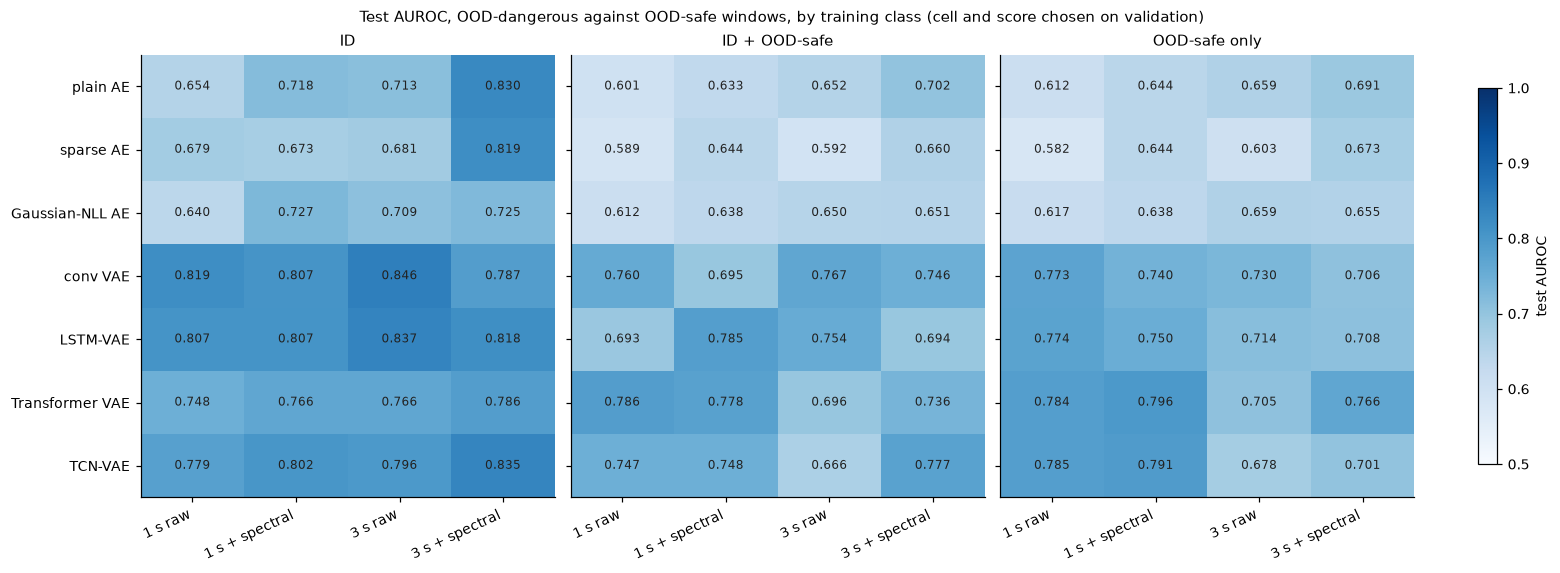

In [4]:
VAL, TEST = 'val AUROC, dangerous vs OOD-safe', 'test AUROC, dangerous vs OOD-safe'
METRICS = [TEST, 'test AUROC, dangerous vs all safe', 'test flagged, dangerous (%)', 'test false alarms, OOD-safe (%)',
           'test false alarms, ID-safe (%)']
SETUPS = pd.MultiIndex.from_product([TYPES, INPUTS], names = ['type', 'input'])
cell_mean = scores.groupby(['train_class', 'type', 'input', 'model', 'score'])[[VAL, *METRICS]].mean()
chosen = cell_mean[VAL].groupby(['train_class', 'type', 'input']).idxmax()          # -> (class, type, input, model, score)
rows = []
for c, tp, inp, model, score in chosen:
    sub = scores[(scores['train_class'] == c) & (scores['model'] == model) & (scores['score'] == score)]
    rows.append({'train_class': c, 'type': tp, 'input': inp, 'model': model, 'score': score, 'direction': sub['direction'].mode().iloc[0],
                 'seeds': len(sub), **{f'{m} mean': sub[m].mean() for m in [VAL, *METRICS]}, **{f'{m} sd': sub[m].std() for m in [VAL, *METRICS]}})
best = pd.DataFrame(rows)
best.to_csv(RESULTS / '07_train_class_best.csv', index = False)


def get_grid(frame: pd.DataFrame, value: str) -> pd.DataFrame:
    # (type, input) x training class
    return frame.pivot_table(index = ['type', 'input'], columns = 'train_class', values = value, aggfunc = 'first').reindex(index = SETUPS, columns = CLASSES)


with_sd = best.assign(value = best[f'{TEST} mean'].map('{:.3f}'.format) + ' ± ' + best[f'{TEST} sd'].map('{:.3f}'.format))
display(get_grid(with_sd, 'value').rename(columns = LABEL))
display(get_grid(best.assign(pick = best['model'] + ' | ' + best['score']), 'pick').rename(columns = LABEL))


def plot_panels(grids: dict[str, pd.DataFrame], title: str, label: str, path: Path, fmt: str = '{:.3f}', vmin: float = .5,
                vmax: float = 1.0, cmap: str = 'Blues') -> None:
    # one heatmap per training class: model types (rows) x inputs (columns), annotated, one shared colour bar
    fig, axes = plt.subplots(1, len(grids), figsize = (4.3 * len(grids) + 1.2, 0.5 * len(TYPES) + 1.6), sharey = True,
                             constrained_layout = True, squeeze = False)
    for ax, (name, grid) in zip(axes[0], grids.items()):
        values = grid.to_numpy(dtype = float)
        im = ax.imshow(values, aspect = 'auto', cmap = cmap, vmin = vmin, vmax = vmax)
        for i in range(values.shape[0]):
            for k in range(values.shape[1]):
                if np.isfinite(values[i, k]):
                    strong = abs(values[i, k] - (vmin + vmax) / 2) > .35 * (vmax - vmin)
                    ax.text(k, i, fmt.format(values[i, k]), ha = 'center', va = 'center', fontsize = 8, color = 'white' if strong else '#222')
        ax.set_xticks(range(values.shape[1]), grid.columns, rotation = 25, ha = 'right')
        ax.set_yticks(range(values.shape[0]), grid.index)
        ax.set_title(name, fontsize = 9.5)
    fig.colorbar(im, ax = axes[0], shrink = .85, label = label)
    fig.suptitle(title, fontsize = 10)
    fig.savefig(path, dpi = 160, bbox_inches = 'tight')
    plt.show()


grids = {LABEL[c]: best[best['train_class'] == c].pivot(index = 'type', columns = 'input', values = f'{TEST} mean').reindex(index = TYPES, columns = INPUTS)
         for c in CLASSES}
plot_panels(grids, 'Test AUROC, OOD-dangerous against OOD-safe windows, by training class (cell and score chosen on validation)',
            'test AUROC', FIG_DIR / '07_best_by_setup.png')

## 4. What the training class changes

The change in test AUROC (dangerous against OOD-safe) from training on ID movement to each new class, per (model type,
input), each at its own chosen cell and score; and the alarm at the 1% OOD-safe target: dangerous windows flagged and
OOD-safe false alarms on the test participants.

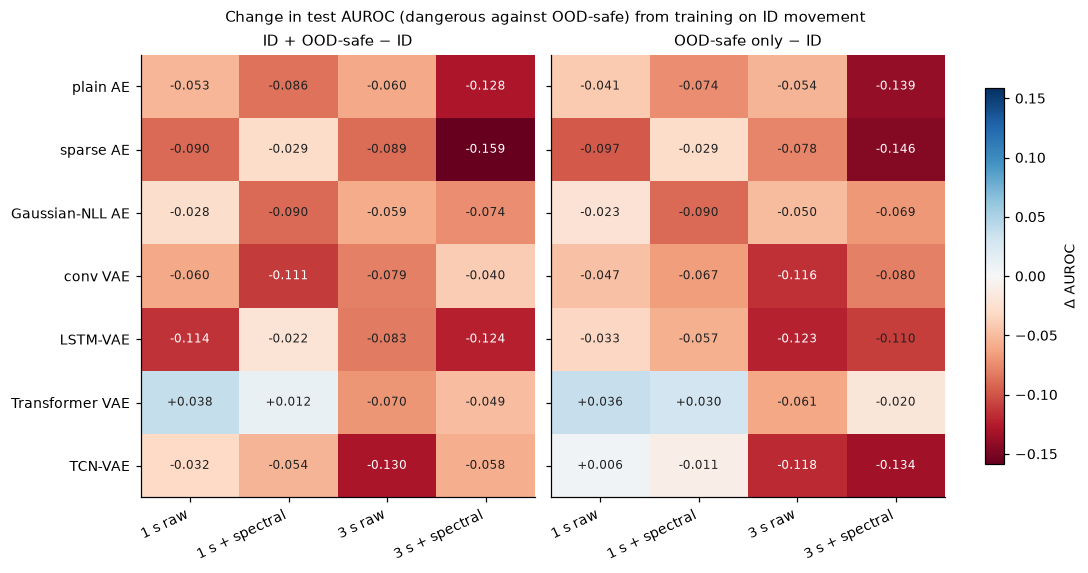

ID + OOD-safe: higher on 2 of 28 set-ups; mean change -0.069 (range -0.159 to +0.038)
OOD-safe only: higher on 3 of 28 set-ups; mean change -0.064 (range -0.146 to +0.036)


dangerous windows flagged (%)                             OOD-safe false alarms (%)                             ID false alarms (%)                            
train_class                                               ID ID + OOD-safe OOD-safe only                        ID ID + OOD-safe OOD-safe only                  ID ID + OOD-safe OOD-safe only
type            input                                                                                                                                                                         
plain AE        1 s raw                                  1.1           0.6           0.6                       1.4           1.8           1.6                 0.0           0.0           0.0
                1 s + spectral                           8.3           2.8           1.5                       2.4           2.4           1.9                 0.0           0.0           0.0
                3 s raw                                  2.7           0.0           0.9                       1.8           2.2           2.3                 0.0           0.0           0.0
                3 s + spectral                          10.0           1.0           1.0                       2.4           1.7           1.8                 0.0           0.0           0.0
sparse AE       1 s raw                                 11.3           0.7           1.0                       1.4           1.5           1.9                 0.0           0.0           0.0
                1 s + spectral                           0.3           2.9           2.7                       2.3           2.1           1.8                 0.0           0.0           0.0
                3 s raw                                  0.3           5.2           1.1                       1.5           1.9           2.6                 0.0           1.2           0.0
                3 s + spectral                           9.5           1.1           0.8                       2.3           2.0           1.7                 0.0           0.0           0.0
Gaussian-NLL AE 1 s raw                                  0.2           0.8           1.0                       1.4           2.0           1.8                 0.0           0.0           0.0
                1 s + spectral                          10.0           3.6           3.3                       1.8           2.5           2.2                 0.1           0.0           0.0
                3 s raw                                  3.4           1.1           1.0                       1.8           2.6           2.6                 0.0           0.0           0.0
                3 s + spectral                           9.1           2.3           2.5                       2.6           2.4           2.2                 0.1           0.0           0.0
conv VAE        1 s raw                                 30.8          18.3          12.5                       1.7           2.4           1.8                 0.0           3.3           1.3
                1 s + spectral                          16.9           4.7           5.3                       2.4           2.0           1.2                 0.8           0.0           0.0
                3 s raw                                 23.8          21.2           8.9                       1.9           3.0           2.7                 0.0           7.9          10.3
                3 s + spectral                          13.1           4.3           6.4                       2.6           2.8           1.4                 0.2           5.0           0.1
LSTM-VAE        1 s raw                                 26.4           3.3          10.8                       2.0           4.3           1.7                 0.0           0.0           0.0
                1 s + spectral                          10.5          14.5           5.6                       1.4           1.7           1.8                 0.1           0.0           0.0
                3 s 

In [5]:
auc = get_grid(best, f'{TEST} mean')
delta = {f'{LABEL[c]} − ID': (auc[c] - auc['ID-safe']).unstack('input').reindex(index = TYPES, columns = INPUTS) for c in CLASSES[1:]}
lim = max(float(np.nanmax(np.abs(d.to_numpy(dtype = float)))) for d in delta.values())
plot_panels(delta, 'Change in test AUROC (dangerous against OOD-safe) from training on ID movement', 'Δ AUROC',
            FIG_DIR / '07_delta_vs_id.png', fmt = '{:+.3f}', vmin = -lim, vmax = lim, cmap = 'RdBu')
for c in CLASSES[1:]:
    d = auc[c] - auc['ID-safe']
    print(f'{LABEL[c]}: higher on {(d > 0).sum()} of {d.notna().sum()} set-ups; mean change {d.mean():+.3f} (range {d.min():+.3f} to {d.max():+.3f})')
alarm = pd.concat({'dangerous windows flagged (%)': get_grid(best, 'test flagged, dangerous (%) mean'),
                   'OOD-safe false alarms (%)': get_grid(best, 'test false alarms, OOD-safe (%) mean'),
                   'ID false alarms (%)': get_grid(best, 'test false alarms, ID-safe (%) mean')}, axis = 1)
display(alarm.rename(columns = LABEL, level = 1).round(1))

## 5. Metric by metric

For each training class and score, the best (model type, input, cell) for that score, chosen on validation, and its test
AUROC; then every score on every set-up (the cell chosen per score on validation), one panel per training class; and how
often each score is the one chosen in section 3.

test AUROC                                                                                                 best set-up                                                                                  \
train_class                      ID ID + OOD-safe OOD-safe only                                                                              ID                                                                   ID + OOD-safe   
score                                                                                                                                                                                                                             
LOF, raw latent               0.838         0.661         0.674                     conv VAE · 3 s raw | VAE · β 1 · learned variance · 3 s raw    TCN-VAE · 3 s + spectral | TCN-VAE · β 1 · learned variance · 3 s + spectral   
LOF, standardized latent      0.839         0.675         0.655                     conv VAE · 3 s raw | VAE · β 1 · learned variance · 3 s raw  LSTM-VAE · 3 s + spectral | LSTM-VAE · β 1 · learned variance · 3 s + spectral   
Mahalanobis, latent           0.830         0.785         0.755                      plain AE · 3 s + spectral | vanilla · 3 s + spectral · 8x4  LSTM-VAE · 1 s + spectral | LSTM-VAE · β 128 · fixed variance · 1 s + spectral   
out-of-range units            0.835         0.676         0.626      TCN-VAE · 3 s + spectral | TCN-VAE · β 1 · fixed variance · 3 s + spectral  LSTM-VAE · 1 s + spectral | LSTM-VAE · β 128 · fixed variance · 1 s + spectral   
reconstruction error          0.725         0.713         0.705  Transformer VAE · 3 s raw | Transformer VAE · β 128 · fixed variance · 3 s raw                LSTM-VAE · 3 s raw | LSTM-VAE · β 128 · fixed variance · 3 s raw   
LOF, active dimensions        0.839         0.675         0.655                     conv VAE · 3 s raw | VAE · β 1 · learned variance · 3 s raw  LSTM-VAE · 3 s + spectral | LSTM-VAE · β 1 · learned variance · 3 s + spectral   
KL                            0.846         0.764         0.753                     conv VAE · 3 s raw | VAE · β 1 · learned variance · 3 s raw  LSTM-VAE · 1 s + spectral | LSTM-VAE · β 128 · fixed variance · 1 s + spectral   
NLL (decoder)                 0.772         0.713         0.705                              conv VAE · 1 s raw | VAE · β 64 · learned variance                LSTM-VAE · 3 s raw | LSTM-VAE · β 128 · fixed variance · 3 s raw   
negative ELBO                 0.772         0.712         0.704                              conv VAE · 1 s raw | VAE · β 64 · learned variance                LSTM-VAE · 3 s raw | LSTM-VAE · β 128 · fixed variance · 3 s raw   
posterior variance            0.818         0.777         0.791    LSTM-VAE · 3 s + spectral | LSTM-VAE · β 1 · fixed variance · 3 s + spectral      TCN-VAE · 3 s + spectral | TCN-VAE · β 1 · fixed variance · 3 s + spectral   

                                                                                                          
train_class                                                                                OOD-safe only  
score                                                                                                     
LOF, raw latent             TCN-VAE · 3 s + spectral | TCN-VAE · β 1 · learned variance · 3 s + spectral  
LOF, standardized latent    TCN-VAE · 3 s + spectral | TCN-VAE · β 1 · learned variance · 3 s + spectral  
Mahalanobis, latent                               LSTM-VAE · 1 s raw | LSTM-VAE · β 128 · fixed variance  
out-of-range units        LSTM-VAE · 1 s + spectral | LSTM-VAE · β 128 · fixed variance · 1 s + spectral  
reconstruction error           conv VAE · 1 s + spectral | VAE · β 128 · fixed variance · 1 s + spectral  
LOF, active dimensions      TCN-VAE · 3 s + spectral | TCN-VAE · β 1 · learned variance · 3 s + spectral  
KL                                                LSTM-VAE · 1 s raw | LSTM-VAE · β 128 · fixed variance  
NLL

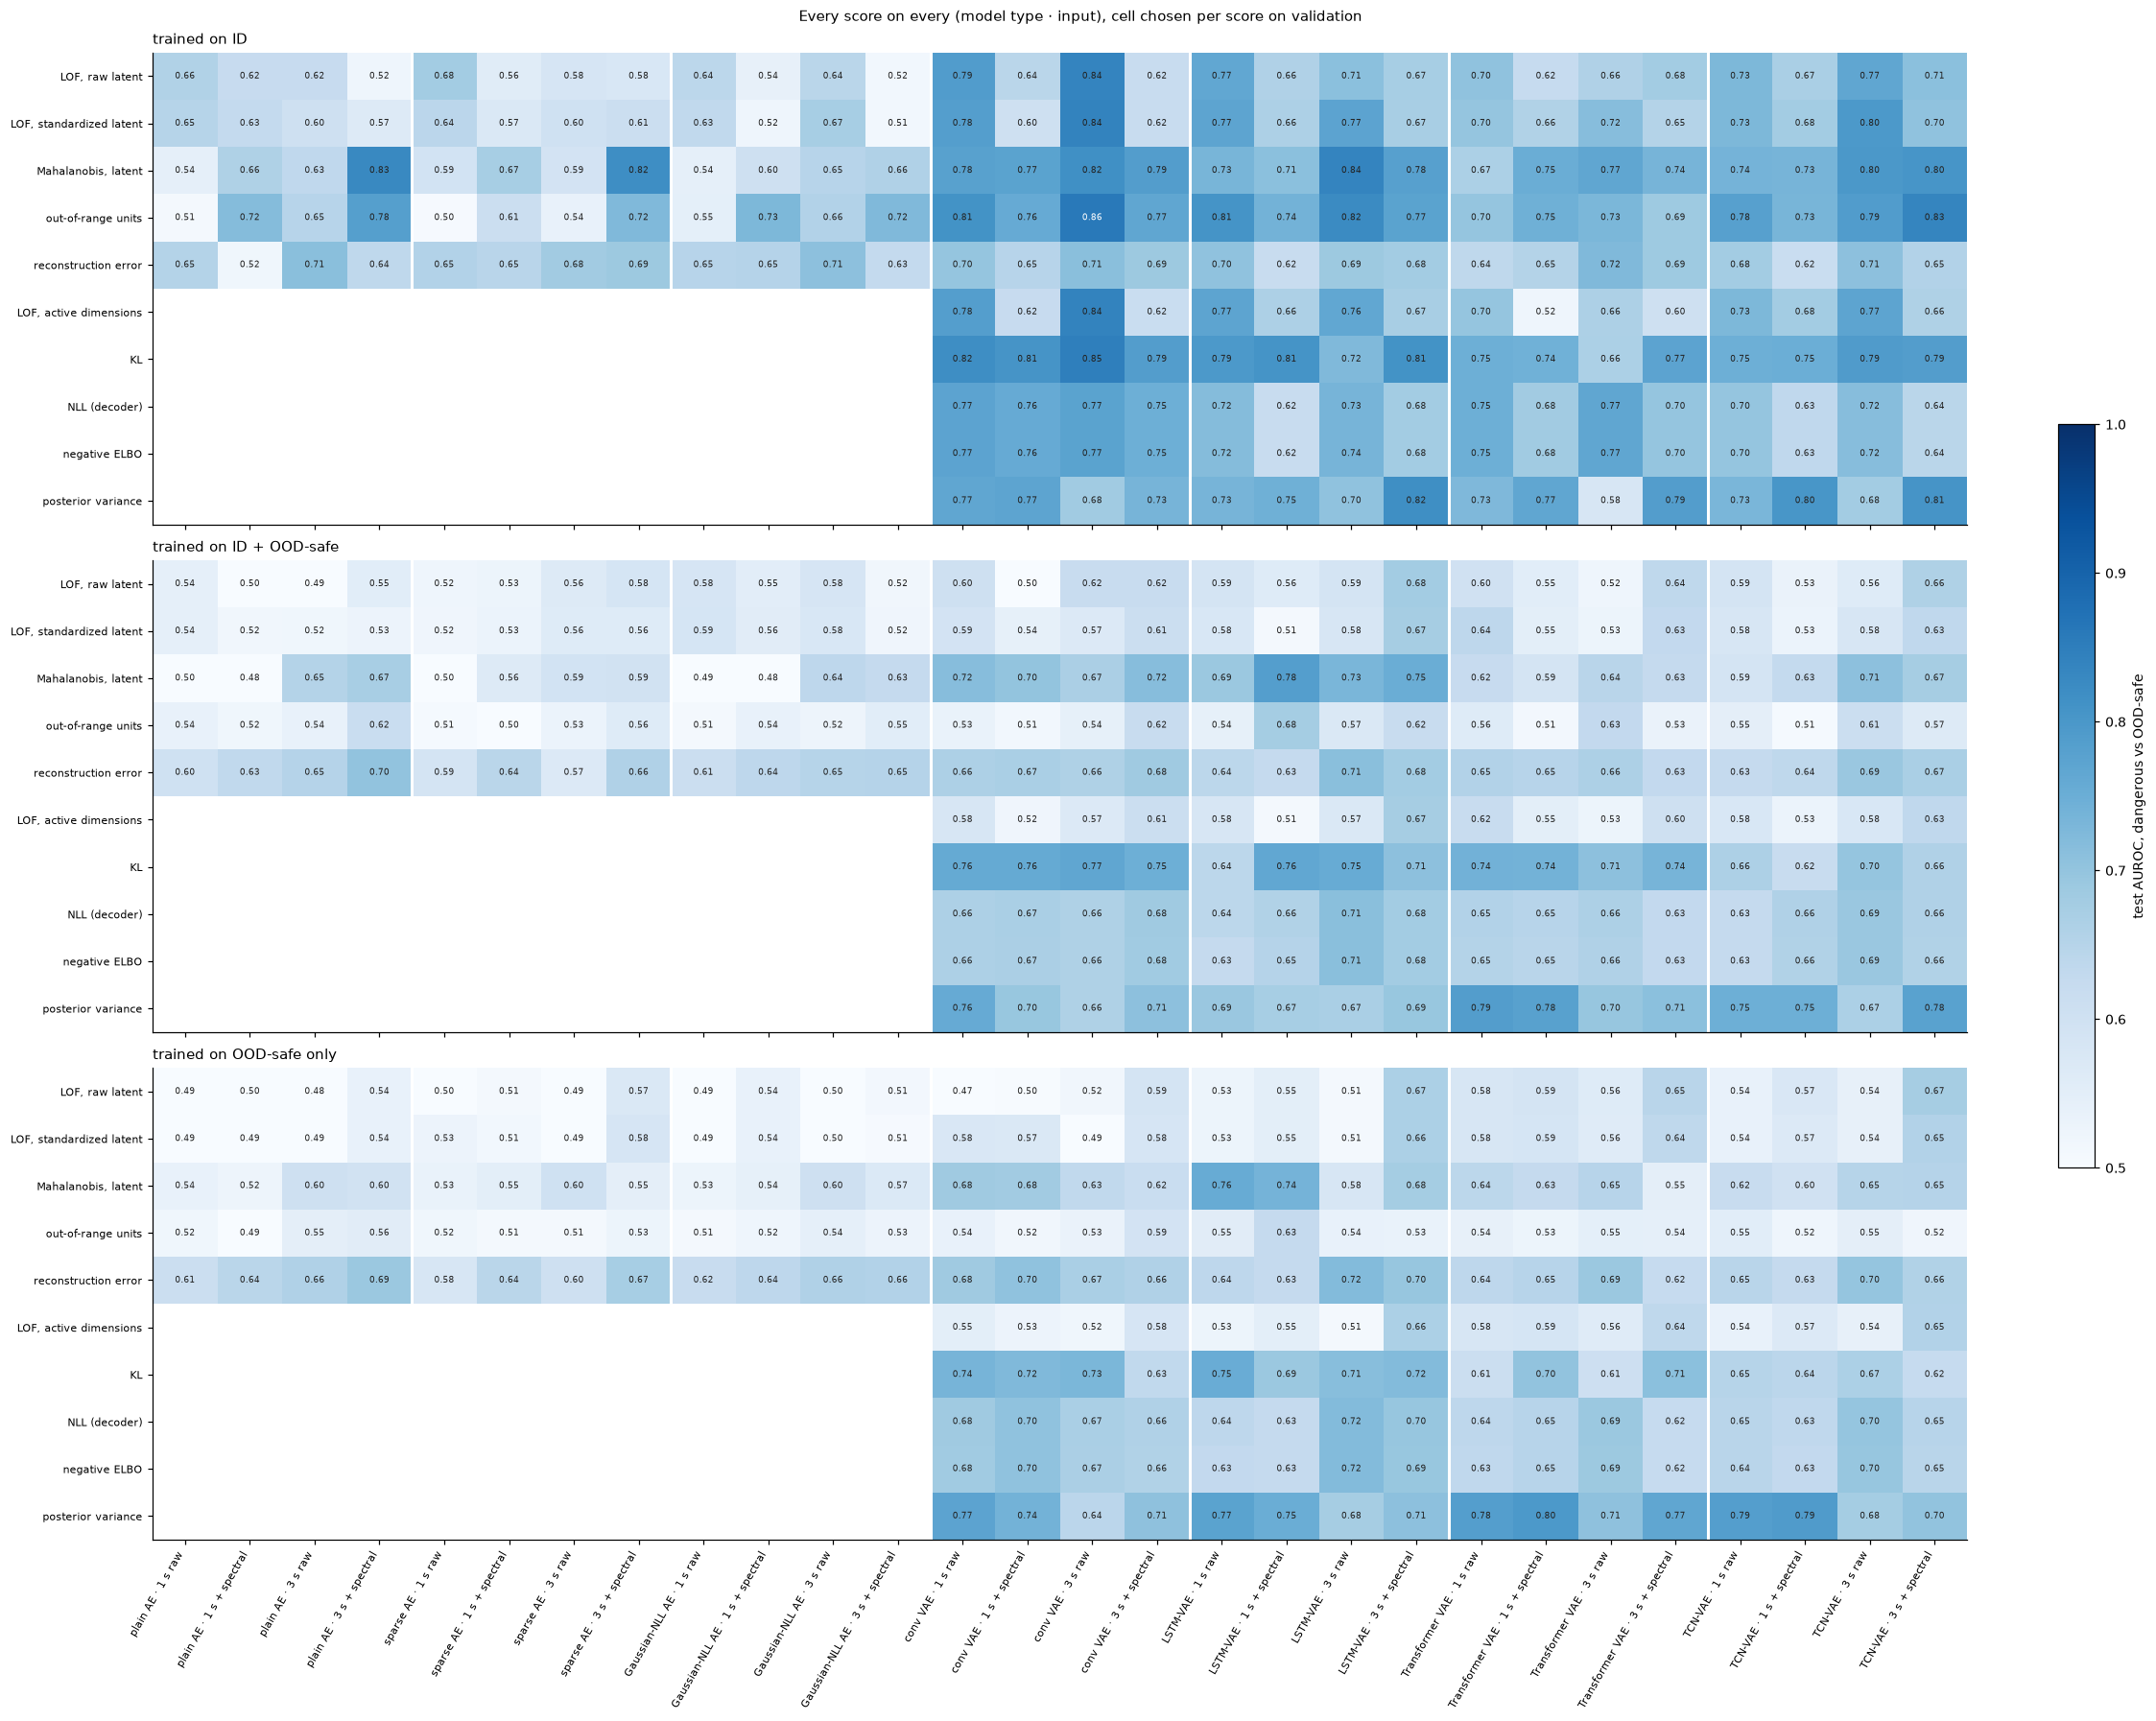

set-ups where the score is chosen,ID,ID + OOD-safe,OOD-safe only
score,,,
KL,6,5,2
"LOF, raw latent",2,0,0
"LOF, standardized latent",1,0,0
"Mahalanobis, latent",5,3,0
out-of-range units,6,0,0
posterior variance,4,10,14
reconstruction error,4,10,12


In [6]:
per_score = cell_mean[VAL].groupby(['train_class', 'score']).idxmax()
metric = pd.DataFrame([{'train_class': c, 'score': s, 'test AUROC': cell_mean.loc[key, TEST], 'set-up': f'{key[1]} · {key[2]} | {key[3]}'}
                       for (c, s), key in per_score.items()])
SCORE_ORDER = [s for s in ns.NATIVE if s in set(metric['score'])]
display(pd.concat({'test AUROC': metric.pivot(index = 'score', columns = 'train_class', values = 'test AUROC').round(3),
                   'best set-up': metric.pivot(index = 'score', columns = 'train_class', values = 'set-up')}, axis = 1)
        .reindex(SCORE_ORDER).reindex(columns = CLASSES, level = 1).rename(columns = LABEL, level = 1))
per_setup = cell_mean[VAL].groupby(['train_class', 'type', 'input', 'score']).idxmax()
setup_auc = pd.Series({k: cell_mean.loc[key, TEST] for k, key in per_setup.items()})
columns = [f'{t} · {i}' for t in TYPES for i in INPUTS]
fig, axes = plt.subplots(len(CLASSES), 1, figsize = (0.62 * len(columns) + 3, (0.42 * len(SCORE_ORDER) + 1.2) * len(CLASSES)),
                         constrained_layout = True)
for ax, c in zip(axes, CLASSES):
    part = setup_auc.loc[c]
    grid = pd.Series({(s, f'{t} · {i}'): v for (t, i, s), v in part.items()}).unstack().reindex(index = SCORE_ORDER, columns = columns)
    im = ax.imshow(grid.to_numpy(dtype = float), aspect = 'auto', cmap = 'Blues', vmin = .5, vmax = 1.0)
    for i in range(grid.shape[0]):
        for k in range(grid.shape[1]):
            v = grid.iat[i, k]
            if np.isfinite(v):
                ax.text(k, i, f'{v:.2f}', ha = 'center', va = 'center', fontsize = 6, color = 'white' if v > .85 else '#222')
    ax.set_xticks(range(len(columns)), columns if c == CLASSES[-1] else [''] * len(columns), rotation = 60, ha = 'right', fontsize = 7)
    ax.set_yticks(range(len(SCORE_ORDER)), SCORE_ORDER, fontsize = 7.5)
    for e in np.arange(len(INPUTS), len(columns), len(INPUTS)) - .5:
        ax.axvline(e, color = 'w', lw = 2)
    ax.set_title(f'trained on {LABEL[c]}', fontsize = 9.5, loc = 'left')
fig.colorbar(im, ax = axes, shrink = .5, label = 'test AUROC, dangerous vs OOD-safe')
fig.suptitle('Every score on every (model type · input), cell chosen per score on validation', fontsize = 10)
fig.savefig(FIG_DIR / '07_metric_by_setup.png', dpi = 160, bbox_inches = 'tight')
plt.show()
display(best.groupby(['score', 'train_class']).size().unstack(fill_value = 0).reindex(columns = CLASSES).rename(columns = LABEL)
        .rename_axis(columns = 'set-ups where the score is chosen'))

## 6. Each dangerous task, and each movement

For every chosen set-up and seed, at its validation threshold: the share of each test task's windows flagged
(`results/07_train_class_per_task.csv`), and per movement (bouts of consecutive in-task windows of at least 2 s, as in
notebook 05, section 8) whether and how soon an alarm fires (`results/07_train_class_bouts.csv`). Shown here for the best
set-up of each training class (chosen on validation).

84 set-ups, 143,892 bouts, 89 s


,model,score,direction,"test AUROC, dangerous vs OOD-safe mean","test AUROC, dangerous vs OOD-safe sd","test flagged, dangerous (%) mean","test false alarms, OOD-safe (%) mean"
train_class,,,,,,,
ID,TCN-VAE · β 1 · fixed variance · 3 s + spectral,out-of-range units,higher = dangerous,0.835,0.008,17.558,2.031
ID + OOD-safe,TCN-VAE · β 1 · fixed variance · 3 s + spectral,posterior variance,higher = dangerous,0.777,0.025,7.040,2.616
OOD-safe only,TCN-VAE · β 1 · learned variance · 1 s + spectral,posterior variance,higher = dangerous,0.791,0.019,3.543,2.343


test AUROC vs OOD-safe                             windows flagged (%)                            
                                 ID ID + OOD-safe OOD-safe only                  ID ID + OOD-safe OOD-safe only
ball_toss                     0.801         0.817         0.806                 7.2           8.7           1.8
sit_to_stand                  0.865         0.803         0.824                17.2           4.6           0.8
step_ups                      0.861         0.557         0.526                15.4           0.0           0.0
tug_of_war                    0.768         0.790         0.814                24.0          15.0          12.2

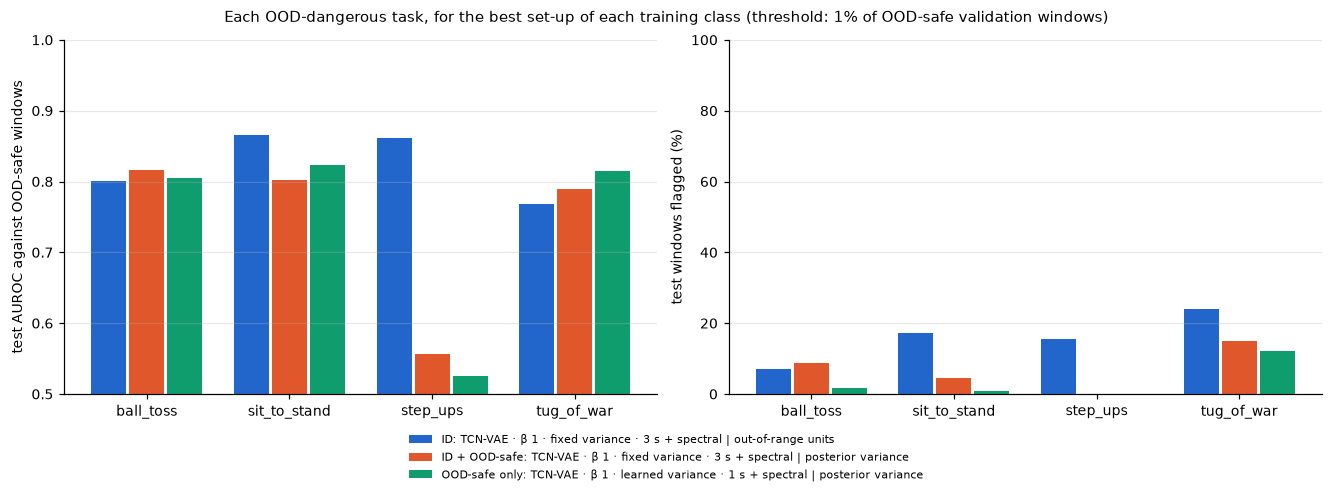

In [7]:
t0 = time.time()
task_rows, bout_rows = [], []
for b in best.itertuples():
    for r in runs[(runs['train_class'] == b.train_class) & (runs['model'] == b.model)].itertuples():
        export, val, keep_v, keep_t, lab_v, lab_t = get_split_data(r)
        v, t = ns.get_native_scores(r.run, export, val, b.score, CACHE)
        metrics, per_task = ns.evaluate_dangerous(v[keep_v], t[keep_t], lab_v, lab_t)
        ident = {'train_class': b.train_class, 'type': b.type, 'input': b.input, 'model': b.model, 'score': b.score, 'seed': r.seed}
        task_rows += [{**ident, 'task': task, 'flagged (%)': share} for task, share in per_task.items()]
        flagged = ns.get_filtered(metrics['sign'] * t[keep_t], lab_t) > metrics['threshold']
        bout_rows.append(ns.get_onset_latency(flagged, lab_t).assign(**ident))
per_task = pd.DataFrame(task_rows)
per_task['controller_class'] = per_task['task'].map(nt.get_controller_class)
bouts = pd.concat(bout_rows, ignore_index = True)
per_task.to_csv(RESULTS / '07_train_class_per_task.csv', index = False)
bouts.to_csv(RESULTS / '07_train_class_bouts.csv', index = False)
print(f'{len(best)} set-ups, {len(bouts):,} bouts, {time.time() - t0:.0f} s')

top = best.loc[best.groupby('train_class')[f'{VAL} mean'].idxmax()].set_index('train_class').reindex(CLASSES)
TOP = {c: f"{LABEL[c]}: {top.loc[c, 'model']} | {top.loc[c, 'score']}" for c in CLASSES}
display(top[['model', 'score', 'direction', f'{TEST} mean', f'{TEST} sd', 'test flagged, dangerous (%) mean',
             'test false alarms, OOD-safe (%) mean']].rename(index = LABEL).round(3))
DANGEROUS_TASKS = sorted(per_task.loc[per_task['controller_class'] == 'OOD-dangerous', 'task'].unique())
task_auc = pd.DataFrame({LABEL[c]: [scores[(scores['train_class'] == c) & (scores['model'] == top.loc[c, 'model'])
                                           & (scores['score'] == top.loc[c, 'score'])][f'test AUROC, {k} vs OOD-safe'].mean()
                                    for k in DANGEROUS_TASKS] for c in CLASSES}, index = DANGEROUS_TASKS)
mine = per_task.merge(top[['model', 'score']].reset_index(), on = ['train_class', 'model', 'score'])
task_flag = mine.groupby(['task', 'train_class'])['flagged (%)'].mean().unstack().reindex(columns = CLASSES)
display(pd.concat({'test AUROC vs OOD-safe': task_auc.round(3),
                   'windows flagged (%)': task_flag.reindex(DANGEROUS_TASKS).rename(columns = LABEL).round(1)}, axis = 1))
fig, axes = plt.subplots(1, 2, figsize = (12, 3.8), constrained_layout = True)
width = .8 / len(CLASSES)
for j, c in enumerate(CLASSES):
    x = np.arange(len(DANGEROUS_TASKS)) + (j - (len(CLASSES) - 1) / 2) * width
    axes[0].bar(x, task_auc[LABEL[c]], width * .92, color = CLASS_C[c], label = TOP[c])
    axes[1].bar(x, task_flag.reindex(DANGEROUS_TASKS)[c], width * .92, color = CLASS_C[c])
for ax, ylabel in zip(axes, ('test AUROC against OOD-safe windows', 'test windows flagged (%)')):
    ax.set_xticks(range(len(DANGEROUS_TASKS)), DANGEROUS_TASKS)
    ax.set(ylabel = ylabel); ax.grid(axis = 'y', alpha = .3)
axes[0].set_ylim(.5, 1.0); axes[1].set_ylim(0, 100)
fig.legend(*axes[0].get_legend_handles_labels(), loc = 'upper center', bbox_to_anchor = (.5, 0), ncol = 1, fontsize = 7.5, frameon = False)
fig.suptitle('Each OOD-dangerous task, for the best set-up of each training class (threshold: 1% of OOD-safe validation windows)', fontsize = 10)
fig.savefig(FIG_DIR / '07_dangerous_tasks.png', dpi = 160, bbox_inches = 'tight')
plt.show()

dangerous movements flagged (%)                             dangerous median latency (s)                             OOD-safe movements alarmed (%)                              \
train_class                                                 ID ID + OOD-safe OOD-safe only                           ID ID + OOD-safe OOD-safe only                             ID ID + OOD-safe OOD-safe only   
type            input                                                                                                                                                                                            
plain AE        1 s raw                                    7.7          17.9          17.9                         15.2          12.6          20.1                            2.4           3.5           3.5   
                1 s + spectral                            46.2          48.7          35.9                         10.5           7.9          18.6                            9.1           5.2           4.3   
                3 s raw                                   17.9           0.0          20.5                         14.7           NaN          23.7                            1.4           1.9           3.0   
                3 s + spectral                            28.2          30.8          28.2                         14.9          16.1          19.7                           12.1           3.8           3.5   
sparse AE       1 s raw                                   30.8          23.1          25.6                          9.9          19.8          23.3                            7.7           3.1           3.7   
                1 s + spectral                            17.9          61.5          46.2                         18.0           4.6           7.7                            9.7           4.8           4.9   
                3 s raw                                    5.1          10.3          23.1                         17.7          10.8          27.3                            0.7           1.9           3.1   
                3 s + spectral                            51.3          25.6          25.6                         14.7          23.2          23.9                           13.7           3.8           3.2   
Gaussian-NLL AE 1 s raw                                    2.6          25.6          17.9                         19.5           9.0          19.0                            4.1           4.7           3.6   
                1 s + spectral                            76.9          64.1          51.3                          4.0           3.9           4.9                           12.1           6.7           5.4   
                3 s raw                                   25.6          23.1          23.1                         15.8          27.1          27.2                            1.8           3.4           3.3   
                3 s + spectral                            53.8          41.0          38.5                         11.5          12.8           8.8                            9.5           4.3           4.0   
conv VAE        1 s raw                                   97.4          46.2          43.6                          1.8           4.9          11.3                           12.3           8.5           6.3   
                1 s + spectral                            76.9          51.3          51.3                          3.5           5.8           4.9                           14.6           9.5           9.1   
                3 s raw                                   38.5          35.9          30.8                         15.7          16.3          15.8                            6.7           5.5           3.0   
                3 s + spectral                            56.4          25.6          48.7                          9.0          15.3           4.7                           11.5           1.6           9.2   
LSTM-VAE        1 s raw                  

median bouts per run: {'ID-safe': 66.0, 'OOD-dangerous': 13.0, 'OOD-safe': 492.0}


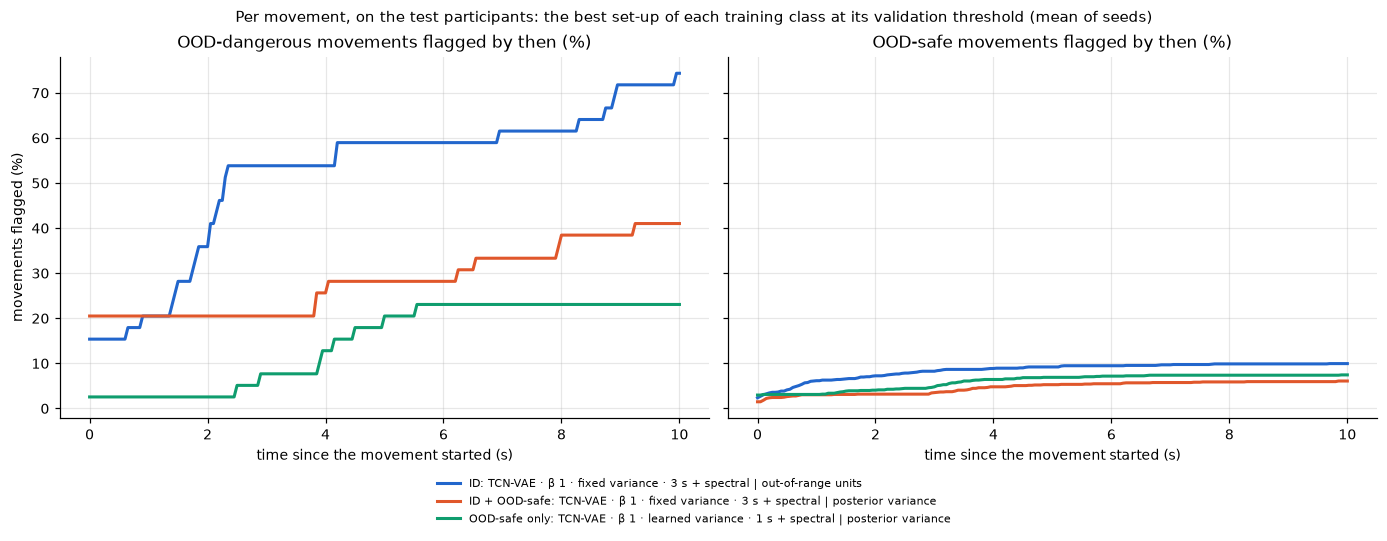

In [8]:
def summarize_bouts(frame: pd.DataFrame) -> pd.Series:
    # share of bouts flagged at all, and the median latency of those flagged
    hit = frame['latency_s'].notna()
    return pd.Series({'bouts': len(frame), 'flagged (%)': 100 * hit.mean(), 'median latency (s)': frame.loc[hit, 'latency_s'].median()})


lat = (bouts.groupby(['train_class', 'type', 'input', 'seed', 'controller_class']).apply(summarize_bouts).reset_index()
       .groupby(['train_class', 'type', 'input', 'controller_class'])[['bouts', 'flagged (%)', 'median latency (s)']].mean())
movement = pd.concat({'dangerous movements flagged (%)': lat['flagged (%)'].xs('OOD-dangerous', level = 'controller_class'),
                      'dangerous median latency (s)': lat['median latency (s)'].xs('OOD-dangerous', level = 'controller_class'),
                      'OOD-safe movements alarmed (%)': lat['flagged (%)'].xs('OOD-safe', level = 'controller_class'),
                      'ID movements alarmed (%)': lat['flagged (%)'].xs('ID-safe', level = 'controller_class')}, axis = 1)
show = movement.unstack('train_class').reindex(SETUPS).reindex(columns = CLASSES, level = 1).rename(columns = LABEL, level = 1)
display(show.round(1))
print('median bouts per run:', bouts.groupby(['train_class', 'model', 'seed', 'controller_class']).size().groupby('controller_class').median().to_dict())
grid_s = np.linspace(0, 10, 201)
fig, axes = plt.subplots(1, 2, figsize = (12.5, 4.2), sharey = True, constrained_layout = True)
for ax, kind in zip(axes, ('OOD-dangerous', 'OOD-safe')):
    for c in CLASSES:
        part = bouts[(bouts['train_class'] == c) & (bouts['model'] == top.loc[c, 'model']) & (bouts['score'] == top.loc[c, 'score'])
                     & (bouts['controller_class'] == kind)]
        curve = np.mean([[(sub['latency_s'] <= x).mean() * 100 for x in grid_s] for _, sub in part.groupby('seed')], axis = 0)
        ax.plot(grid_s, curve, color = CLASS_C[c], lw = 2, label = TOP[c])
    ax.set(xlabel = 'time since the movement started (s)', title = f'{kind} movements flagged by then (%)'); ax.grid(alpha = .3)
axes[0].set_ylabel('movements flagged (%)')
fig.legend(*axes[0].get_legend_handles_labels(), loc = 'upper center', bbox_to_anchor = (.5, 0), ncol = 1, fontsize = 7.5, frameon = False)
fig.suptitle('Per movement, on the test participants: the best set-up of each training class at its validation threshold (mean of seeds)', fontsize = 10)
fig.savefig(FIG_DIR / '07_onset_latency.png', dpi = 160, bbox_inches = 'tight')
plt.show()

## 7. A supervised reference: is the difference in the latent at all?

The scores above are unsupervised: they never see a dangerous window. As a reference, a logistic regression on each run's
latent (posterior means for a VAE), fitted on the validation participants' OOD-dangerous and OOD-safe windows (a balanced
sample of 40,000) and scored on the test participants: how well a classifier trained with these labels could read
dangerous movement out of the latent, on new people. It has seen the dangerous tasks, so it says nothing about movement
it has never seen; it measures how much of the dangerous-versus-safe difference each training class leaves in the latent.
Written to `results/07_train_class_probe.csv`.

computed 07_train_class_probe.csv for 774 runs in 1.3 min
774 rows in notebooks/nature/model_exploration/onboard/results/07_train_class_probe.csv


train_class                                ID  ID + OOD-safe  OOD-safe only
type            input                                                      
plain AE        1 s raw         0.829 ± 0.026  0.835 ± 0.009  0.842 ± 0.004
                1 s + spectral  0.886 ± 0.002  0.897 ± 0.005  0.903 ± 0.005
                3 s raw         0.854 ± 0.019  0.882 ± 0.004  0.874 ± 0.006
                3 s + spectral  0.910 ± 0.002  0.914 ± 0.003  0.915 ± 0.002
sparse AE       1 s raw         0.827 ± 0.060  0.834 ± 0.014  0.826 ± 0.028
                1 s + spectral  0.830 ± 0.057  0.896 ± 0.001  0.896 ± 0.002
                3 s raw         0.831 ± 0.024  0.857 ± 0.036  0.870 ± 0.009
                3 s + spectral  0.879 ± 0.027  0.908 ± 0.009  0.915 ± 0.001
Gaussian-NLL AE 1 s raw         0.803 ± 0.035  0.837 ± 0.008  0.841 ± 0.001
                1 s + spectral  0.875 ± 0.009  0.898 ± 0.000  0.900 ± 0.002
                3 s raw         0.842 ± 0.011  0.858 ± 0.017  0.863 ± 0.015
                3 s + spectral  0.906 ± 0.009  0.909 ± 0.001  0.914 ± 0.005
conv VAE        1 s raw         0.875 ± 0.013  0.871 ± 0.008  0.872 ± 0.011
                1 s + spectral  0.903 ± 0.009  0.906 ± 0.003  0.911 ± 0.006
                3 s raw         0.893 ± 0.015  0.886 ± 0.017  0.911 ± 0.009
                3 s + spectral  0.908 ± 0.004  0.921 ± 0.004  0.916 ± 0.005
LSTM-VAE        1 s raw         0.844 ± 0.006  0.842 ± 0.005  0.849 ± 0.017
                1 s + spectral  0.857 ± 0.019  0.892 ± 0.002  0.894 ± 0.001
                3 s raw         0.854 ± 0.008  0.871 ± 0.030  0.859 ± 0.007
                3 s + spectral  0.877 ± 0.005  0.914 ± 0.005  0.913 ± 0.001
Transformer VAE 1 s raw         0.831 ± 0.018  0.841 ± 0.021  0.843 ± 0.017
                1 s + spectral  0.885 ± 0.002  0.897 ± 0.003  0.899 ± 0.007
                3 s raw         0.845 ± 0.016  0.866 ± 0.012  0.865 ± 0.020
                3 s + spectral  0.905 ± 0.009  0.900 ± 0.013  0.905 ± 0.005
TCN-VAE         1 s raw         0.841 ± 0.015  0.871 ± 0.002  0.875 ± 0.002
                1 s + spectral  0.883 ± 0.011  0.899 ± 0.002  0.901 ± 0.001
                3 s raw         0.872 ± 0.017  0.880 ± 0.029  0.867 ± 0.019
                3 s + spectral  0.905 ± 0.004  0.924 ± 0.005  0.917 ± 0.004

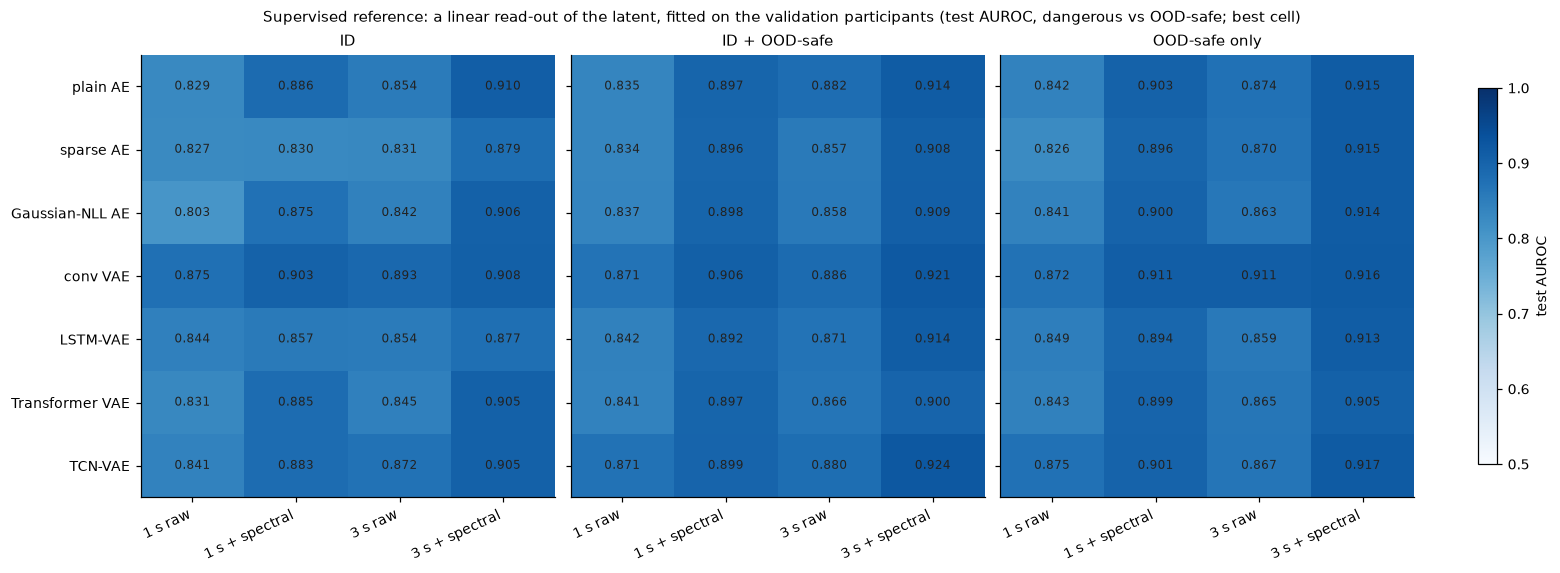

mean over set-ups, best unsupervised score against the best probe:


,best unsupervised score,linear probe
train_class,,
ID,0.763,0.866
ID + OOD-safe,0.695,0.882
OOD-safe only,0.699,0.884


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROBE_WINDOWS = 40_000


def probe_runs() -> pd.DataFrame:
    rows = []
    for r in runs.itertuples():
        export, val, keep_v, keep_t, lab_v, lab_t = get_split_data(r)
        z_v = ns.get_array(val, 'z')[keep_v]                                     # (N_val, 32)
        z_t = ns.get_array(export, 'z')[~export['is_train']][keep_t]             # (N_test, 32)
        cls_v, cls_t = lab_v['controller_class'].astype(str).to_numpy(), lab_t['controller_class'].astype(str).to_numpy()
        rng_p = np.random.default_rng(r.seed)
        fit = np.concatenate([rng_p.choice(np.flatnonzero(cls_v == c), PROBE_WINDOWS // 2, replace = False) for c in (ns.DANGEROUS, ns.SAFE)])
        probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter = 2000)).fit(z_v[fit], cls_v[fit] == ns.DANGEROUS)
        p = probe.decision_function(z_t)
        dang, safe, ident = cls_t == ns.DANGEROUS, cls_t == ns.SAFE, cls_t == ns.ID
        rows.append({'train_class': r.train_class, 'type': r.type, 'input': r.input, 'model': r.model, 'seed': r.seed,
                     'probe AUROC, dangerous vs OOD-safe': ns.get_auroc(p[dang], np.sort(p[safe])),
                     'probe AUROC, dangerous vs all safe': ns.get_auroc(p[dang], np.sort(p[safe | ident]))})
    return pd.DataFrame(rows)


probes = get_table(RESULTS / '07_train_class_probe.csv', probe_runs)
PROBE = 'probe AUROC, dangerous vs OOD-safe'
probe_cell = probes.groupby(['train_class', 'type', 'input', 'model'])[PROBE].agg(['mean', 'std'])
probe_best = probe_cell.loc[probe_cell.groupby(['train_class', 'type', 'input'])['mean'].idxmax()].reset_index()
display(get_grid(probe_best.assign(value = probe_best['mean'].map('{:.3f}'.format) + ' ± ' + probe_best['std'].map('{:.3f}'.format)), 'value')
        .rename(columns = LABEL))
grids_p = {LABEL[c]: probe_best[probe_best['train_class'] == c].pivot(index = 'type', columns = 'input', values = 'mean').reindex(index = TYPES, columns = INPUTS)
           for c in CLASSES}
plot_panels(grids_p, 'Supervised reference: a linear read-out of the latent, fitted on the validation participants (test AUROC, dangerous vs OOD-safe; best cell)',
            'test AUROC', FIG_DIR / '07_probe_by_setup.png')
both = probe_best.merge(best[['train_class', 'type', 'input', f'{TEST} mean']], on = ['train_class', 'type', 'input'])
print('mean over set-ups, best unsupervised score against the best probe:')
display(both.groupby('train_class')[[f'{TEST} mean', 'mean']].mean().rename(index = LABEL, columns = {f'{TEST} mean': 'best unsupervised score', 'mean': 'linear probe'}).round(3))

## 8. Latent spaces

How much does the training class change a model's latent, and does dangerous movement separate in it? Linear CKA (1 =
the same latent up to rotation and scale, notebook 05, section 9.4) between every retrained run and its ID-trained twin
(seed 0, the same 4,000 test windows); then the test windows of the best set-up of each training class (up to 150 per
task, seed 0) in UMAP, coloured by controller class, and as one interactive 3-D page
(`interactive/07_train_class_best_3d.html`; the dropdown switches training class, view and lens).

In [10]:
rng = np.random.default_rng(0)
test_keys = long.loc[(long['split'] == 'test') & long['in_task'], ['rec', 'end']].reset_index(drop = True)
sample_keys = test_keys.iloc[np.sort(rng.choice(len(test_keys), 4000, replace = False))].reset_index(drop = True)


def get_test_z(run: Path, inputs: str, keys: pd.DataFrame) -> np.ndarray:
    # a run's exported test latents (posterior means for a VAE) for the windows named by keys, in that order
    data = np.load(run / 'latents.npz')
    labels = ns.get_labels(tables[inputs], data['rows'])
    return lv.get_aligned_z({'labels': labels[~data['is_train']].reset_index(drop = True), 'z': data['z'][~data['is_train']]}, keys)


seed0 = runs[runs['seed'] == runs['seed'].min()].set_index(['train_class', 'name'])
cka_rows = []
for (c, name), r in seed0.loc[CLASSES[1:]].iterrows():
    twin = seed0.loc[('ID-safe', name)]
    cka_rows.append({'train_class': c, 'type': r['type'], 'input': r['input'], 'model': r['model'],
                     'CKA with the ID-trained twin': ns.get_linear_cka(get_test_z(r['run'], r['inputs'], sample_keys),
                                                                     get_test_z(twin['run'], twin['inputs'], sample_keys))})
cka = pd.DataFrame(cka_rows)
cka.to_csv(RESULTS / '07_train_class_cka.csv', index = False)
display(cka.pivot_table(index = 'type', columns = ['train_class', 'input'], values = 'CKA with the ID-trained twin', aggfunc = 'mean')
        .reindex(TYPES).reindex(columns = INPUTS, level = 1).rename(columns = LABEL, level = 0).round(2))

train_class     ID + OOD-safe                                       OOD-safe only                                      
input                 1 s raw 1 s + spectral 3 s raw 3 s + spectral       1 s raw 1 s + spectral 3 s raw 3 s + spectral
type                                                                                                                   
plain AE                 0.78           0.78    0.72           0.66          0.80           0.77    0.55           0.66
sparse AE                0.00           0.11    0.31           0.03          0.00           0.13    0.33           0.01
Gaussian-NLL AE          0.75           0.46    0.61           0.76          0.76           0.76    0.61           0.81
conv VAE                 0.61           0.67    0.63           0.70          0.59           0.64    0.60           0.63
LSTM-VAE                 0.48           0.47    0.51           0.53          0.47           0.45    0.50           0.54
Transformer VAE          0.58           0.59    0.63           0.61          0.61           0.56    0.63           0.58
TCN-VAE                  0.59           0.61    0.53           0.59          0.44           0.62    0.56           0.55

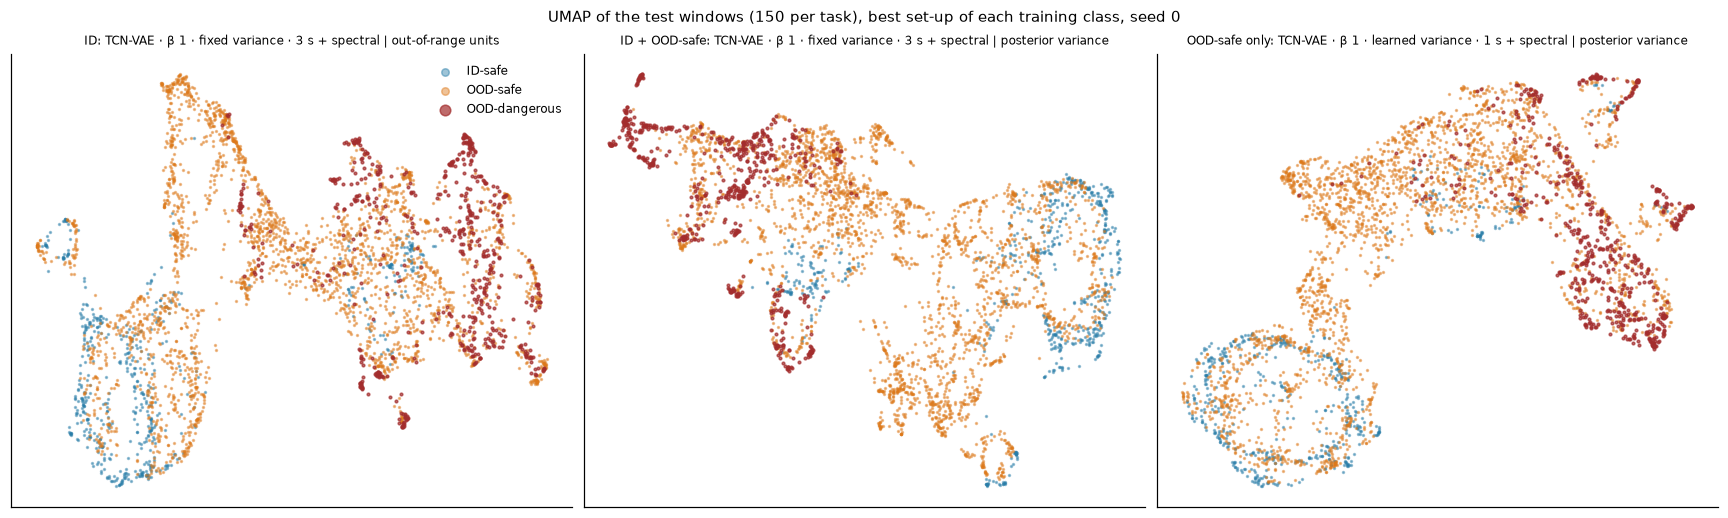

3-D page: notebooks/nature/model_exploration/onboard/interactive/07_train_class_best_3d.html


In [11]:
per_task_n = 150
test_rows = long[(long['split'] == 'test') & long['in_task']].reset_index(drop = True)
pick = np.sort(np.concatenate([rng.choice(np.flatnonzero(test_rows['task'].astype(str).to_numpy() == task),
                                          min(per_task_n, int((test_rows['task'] == task).sum())), replace = False)
                               for task in test_rows['task'].astype(str).unique()]))
shown = test_rows.iloc[pick].reset_index(drop = True)
views = {}
for c in CLASSES:
    r = runs[(runs['train_class'] == c) & (runs['model'] == top.loc[c, 'model'])].sort_values('seed').iloc[0]
    views[TOP[c]] = lv.get_views(get_test_z(r['run'], r['inputs'], shown), VIEW_CACHE)
fig, axes = plt.subplots(1, len(CLASSES), figsize = (5.2 * len(CLASSES), 4.6), constrained_layout = True)
cls = shown['controller_class'].astype(str).to_numpy()
for ax, (name, v) in zip(axes, views.items()):
    pts = v[('UMAP', 2)]
    for label, color in lv.CLASS_C.items():
        m = cls == label
        ax.scatter(pts[m, 0], pts[m, 1], s = 3 if label == 'OOD-dangerous' else 1.5, color = color, alpha = .7 if label == 'OOD-dangerous' else .45,
                   rasterized = True, label = label)
    ax.set_title(name, fontsize = 8)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(fontsize = 8, frameon = False, markerscale = 4)
fig.suptitle(f'UMAP of the test windows ({per_task_n} per task), best set-up of each training class, seed 0', fontsize = 10)
fig.savefig(FIG_DIR / '07_latents_best.png', dpi = 160, bbox_inches = 'tight')
plt.show()
STYLES = lv.get_task_styles(nt.TASK_FAMILIES)
lenses = {'controller class': ('controller_class', lv.CLASS_C), 'family': ('family', lv.FAMILY_C),
          'task': ('task', {t: STYLES[t]['family'] for ts in nt.TASK_FAMILIES.values() for t in ts})}
page = lv.build_3d({name: {k: v[k] for k in v if k != 'units'} for name, v in views.items()}, shown, lenses,
                   {t: s['symbol'] for t, s in STYLES.items()}, 'Best set-up of each training class')
page.write_html(INTERACTIVE / '07_train_class_best_3d.html', include_plotlyjs = 'cdn', config = {'scrollZoom': True, 'displaylogo': False})
print(f"3-D page: {(INTERACTIVE / '07_train_class_best_3d.html').relative_to(REPO)}")

## 9. What this shows

- **Section 3–4: safe training removes the novelty signal.** The new classes lower the chosen AUROC on 26 and 25 of the
  28 set-ups, by 0.07 on average (up to 0.16). Even trained on ID alone the models separate dangerous from safe movement
  far less well (0.763 on average) than unfamiliar from familiar (up to 0.963, notebook 05): every OOD task is unfamiliar
  to them.
- **Section 5: the useful score changes.** With safe movement in training the chosen score is mostly reconstruction error
  or posterior variance; LOF is almost never chosen.
- **Section 6: per task and movement.** Step-ups are near chance for every model trained on safe movement; the ball toss
  and sit-to-stand lose a little, tug of war gains slightly.
- **Section 7: the supervised read-out reaches 0.80 to 0.92**, 0.10 to 0.19 above the novelty scores, and the rhythm
  features help it, unlike in notebook 05; the TCN-VAE's latents give the best read-out (0.924).
- **Section 8: retraining reshapes the latents** (linear CKA with the ID-trained twin about 0.5 to 0.8 for most types,
  about 0.5 for the LSTM-VAE and the TCN-VAE, 0 to 0.33 for the sparse AE).
- **Limits.** The read-out has seen all four dangerous tasks, so it says nothing about unseen ones; the four-task danger
  label is itself uncertain (data exploration notebook 04 found only the ball toss clearly dangerous by estimator error).